# norveç konut şarj verisi

zenodo kaydındaki dört dosyadan sadece Dataset1_charging_reports.csv gerçek ölçüm. diğer üçü bu oturumlardan hesaplanmış tahmin olduğu için kullanmıyorum. bu notebookta dosyanın yapısına bakıp saatlik bağlı araç sayısını çıkarıyorum.

dosya noktalı virgülle ayrılmış ve ondalıklar virgüllü. connection_time tarih değil, saat cinsinden bağlı kalma süresi.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

reports = pd.read_csv(
    project_dir / "data" / "raw" / "Dataset1_charging_reports.csv",
    sep=";", decimal=",", parse_dates=["plugin_time", "plugout_time"],
)
print("satır ve sütun:", reports.shape)
print("lokasyon:", reports["location"].nunique(), "kullanıcı:", reports["user_id"].nunique())
print("tekrar eden session_id:", reports["session_id"].duplicated().sum())
print(reports.isna().sum())
reports.head()

satır ve sütun: (35377, 7)
lokasyon: 12 kullanıcı: 267
tekrar eden session_id: 0
location            0
user_id             0
session_id          0
plugin_time         0
plugout_time       38
connection_time    38
energy_session      0
dtype: int64


,location,user_id,session_id,plugin_time,plugout_time,connection_time,energy_session
0,ASK,ASK_Plass15,ASK_18266,2019-11-28 19:08:00,2019-11-29 08:20:00,13.20000,19.96
1,ASK,ASK_Plass15,ASK_14220,2019-09-02 20:23:00,2019-09-03 07:48:00,11.41667,21.34
2,ASK,ASK_Plass15,ASK_20447,2020-01-08 17:35:00,2020-01-09 07:49:00,14.23333,19.85
3,ASK,ASK_Plass15,ASK_13858,2019-08-23 18:10:00,2019-08-24 09:22:00,15.20000,24.50
4,ASK,ASK_Plass15,ASK_16687,2019-10-30 20:14:00,2019-10-31 08:10:00,11.93333,18.50


lokasyonların ilk ve son kayıtları ile süre ve enerji dağılımı. her lokasyon farklı bir dönemi kapsıyor.

In [2]:
by_location = reports.groupby("location")["plugin_time"].agg(ilk="min", son="max", oturum="count")
print(by_location)
reports[["connection_time", "energy_session"]].describe()

                         ilk                 son  oturum
location                                                
ASK      2018-11-15 16:15:00 2020-02-03 07:28:00    6372
BAR      2018-09-07 14:13:00 2020-02-02 21:26:00    1969
BAR_2    2020-02-04 17:39:00 2021-08-05 20:50:00    1028
BER      2019-10-31 16:08:00 2020-02-02 19:49:00     308
BOD      2018-10-29 21:07:00 2020-02-02 13:13:00     508
KRO      2021-01-15 14:51:02 2021-05-05 21:49:20     492
OSL_1    2019-10-08 18:28:00 2020-02-02 01:48:00     464
OSL_2    2019-11-25 18:48:00 2020-02-02 21:14:00     127
OSL_S    2018-02-06 14:42:00 2020-02-03 00:00:00    9757
OSL_T    2019-11-15 15:23:00 2021-03-28 21:43:00    5478
TRO      2019-03-08 11:07:00 2020-02-02 20:45:00    2168
TRO_R    2018-12-21 10:20:26 2020-01-31 20:42:06    6706


,connection_time,energy_session
count,35339.000000,35377.000000
mean,12.658947,12.656105
std,13.113476,11.316051
min,0.033889,0.060000
25%,3.450000,5.160000
50%,11.197780,9.030000
75%,15.906110,16.420000
max,119.916700,88.450000


her oturumu acn'deki kuralla saat başlarına açıyorum. bağlanmadan sonraki ilk saat başından ayrılmadan önceki son saat başına kadar oturum bağlı sayılıyor. plugout zamanı boş olan oturumları atıyorum. zamanlar norveç yerel saati, utc'ye çevirmedim.

In [3]:
complete = reports.dropna(subset=["plugin_time", "plugout_time"])
print("plugout zamanı boş olduğu için atılan:", len(reports) - len(complete))

rows = []
for item in complete.itertuples():
    hours = pd.date_range(
        item.plugin_time.ceil("h"), item.plugout_time.ceil("h"), freq="h", inclusive="left"
    )
    rows.extend((item.location, hour) for hour in hours)

hourly = pd.DataFrame(rows, columns=["location", "hour"])
connected = hourly.groupby(["location", "hour"]).size().rename("connected").reset_index()
print("saatlik kayıt:", connected.shape)
print("bir saatte aynı lokasyonda en çok bağlı araç:", connected["connected"].max())

plugout zamanı boş olduğu için atılan: 38


saatlik kayıt: (90383, 3)
bir saatte aynı lokasyonda en çok bağlı araç: 34


üç grafik: lokasyona göre oturum sayısı, bağlı kalma süresi ve günün saatine göre ortalama bağlı araç sayısı.

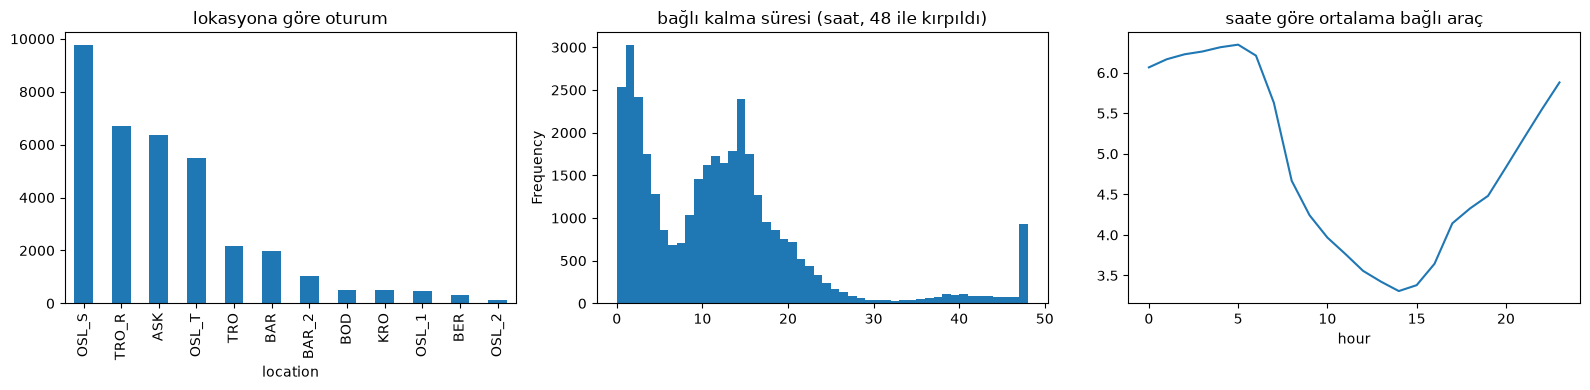

In [4]:
figure_dir = project_dir / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
reports["location"].value_counts().plot.bar(ax=axes[0], title="lokasyona göre oturum")
reports["connection_time"].clip(upper=48).plot.hist(
    bins=48, ax=axes[1], title="bağlı kalma süresi (saat, 48 ile kırpıldı)"
)
connected.groupby(connected["hour"].dt.hour)["connected"].mean().plot(
    ax=axes[2], title="saate göre ortalama bağlı araç"
)
plt.tight_layout()
plt.savefig(figure_dir / "norvec_eda.png", dpi=150)
plt.show()